## CS440 Assignment 3
Transformers for Retrieval and Translation

**Deadline:** November 24, 2026 at 10:00 PM Eastern Time. **Total:** 100 points. Teams may have up to four members. Submit one `hw3.ipynb` per team on Gradescope and add all members. Late submissions receive 0 points. Read HW3.pdf for the instructions and integrity policy.

### Setup
Run `setup.sh` and select the CS440 HW3 kernel. Use Python 3.12 and CPU PyTorch 2.14.1. Save before `check()`, which loads your saved code and answers and checks their formats.

In [ ]:
from pathlib import Path
import sys
# Run from the extracted starter directory. Data is included.
sys.path.insert(0, str(Path("code").resolve()))
from hw3lib.runtime import torch, nn, np, configure
from hw3lib.attention import BookAttention
from hw3lib.notebook import check, load_submission
configure(440)
print("PyTorch", torch.__version__, "CPU threads", torch.get_num_threads())

### Problem 1 (50 points)

<div style="max-width:800px">

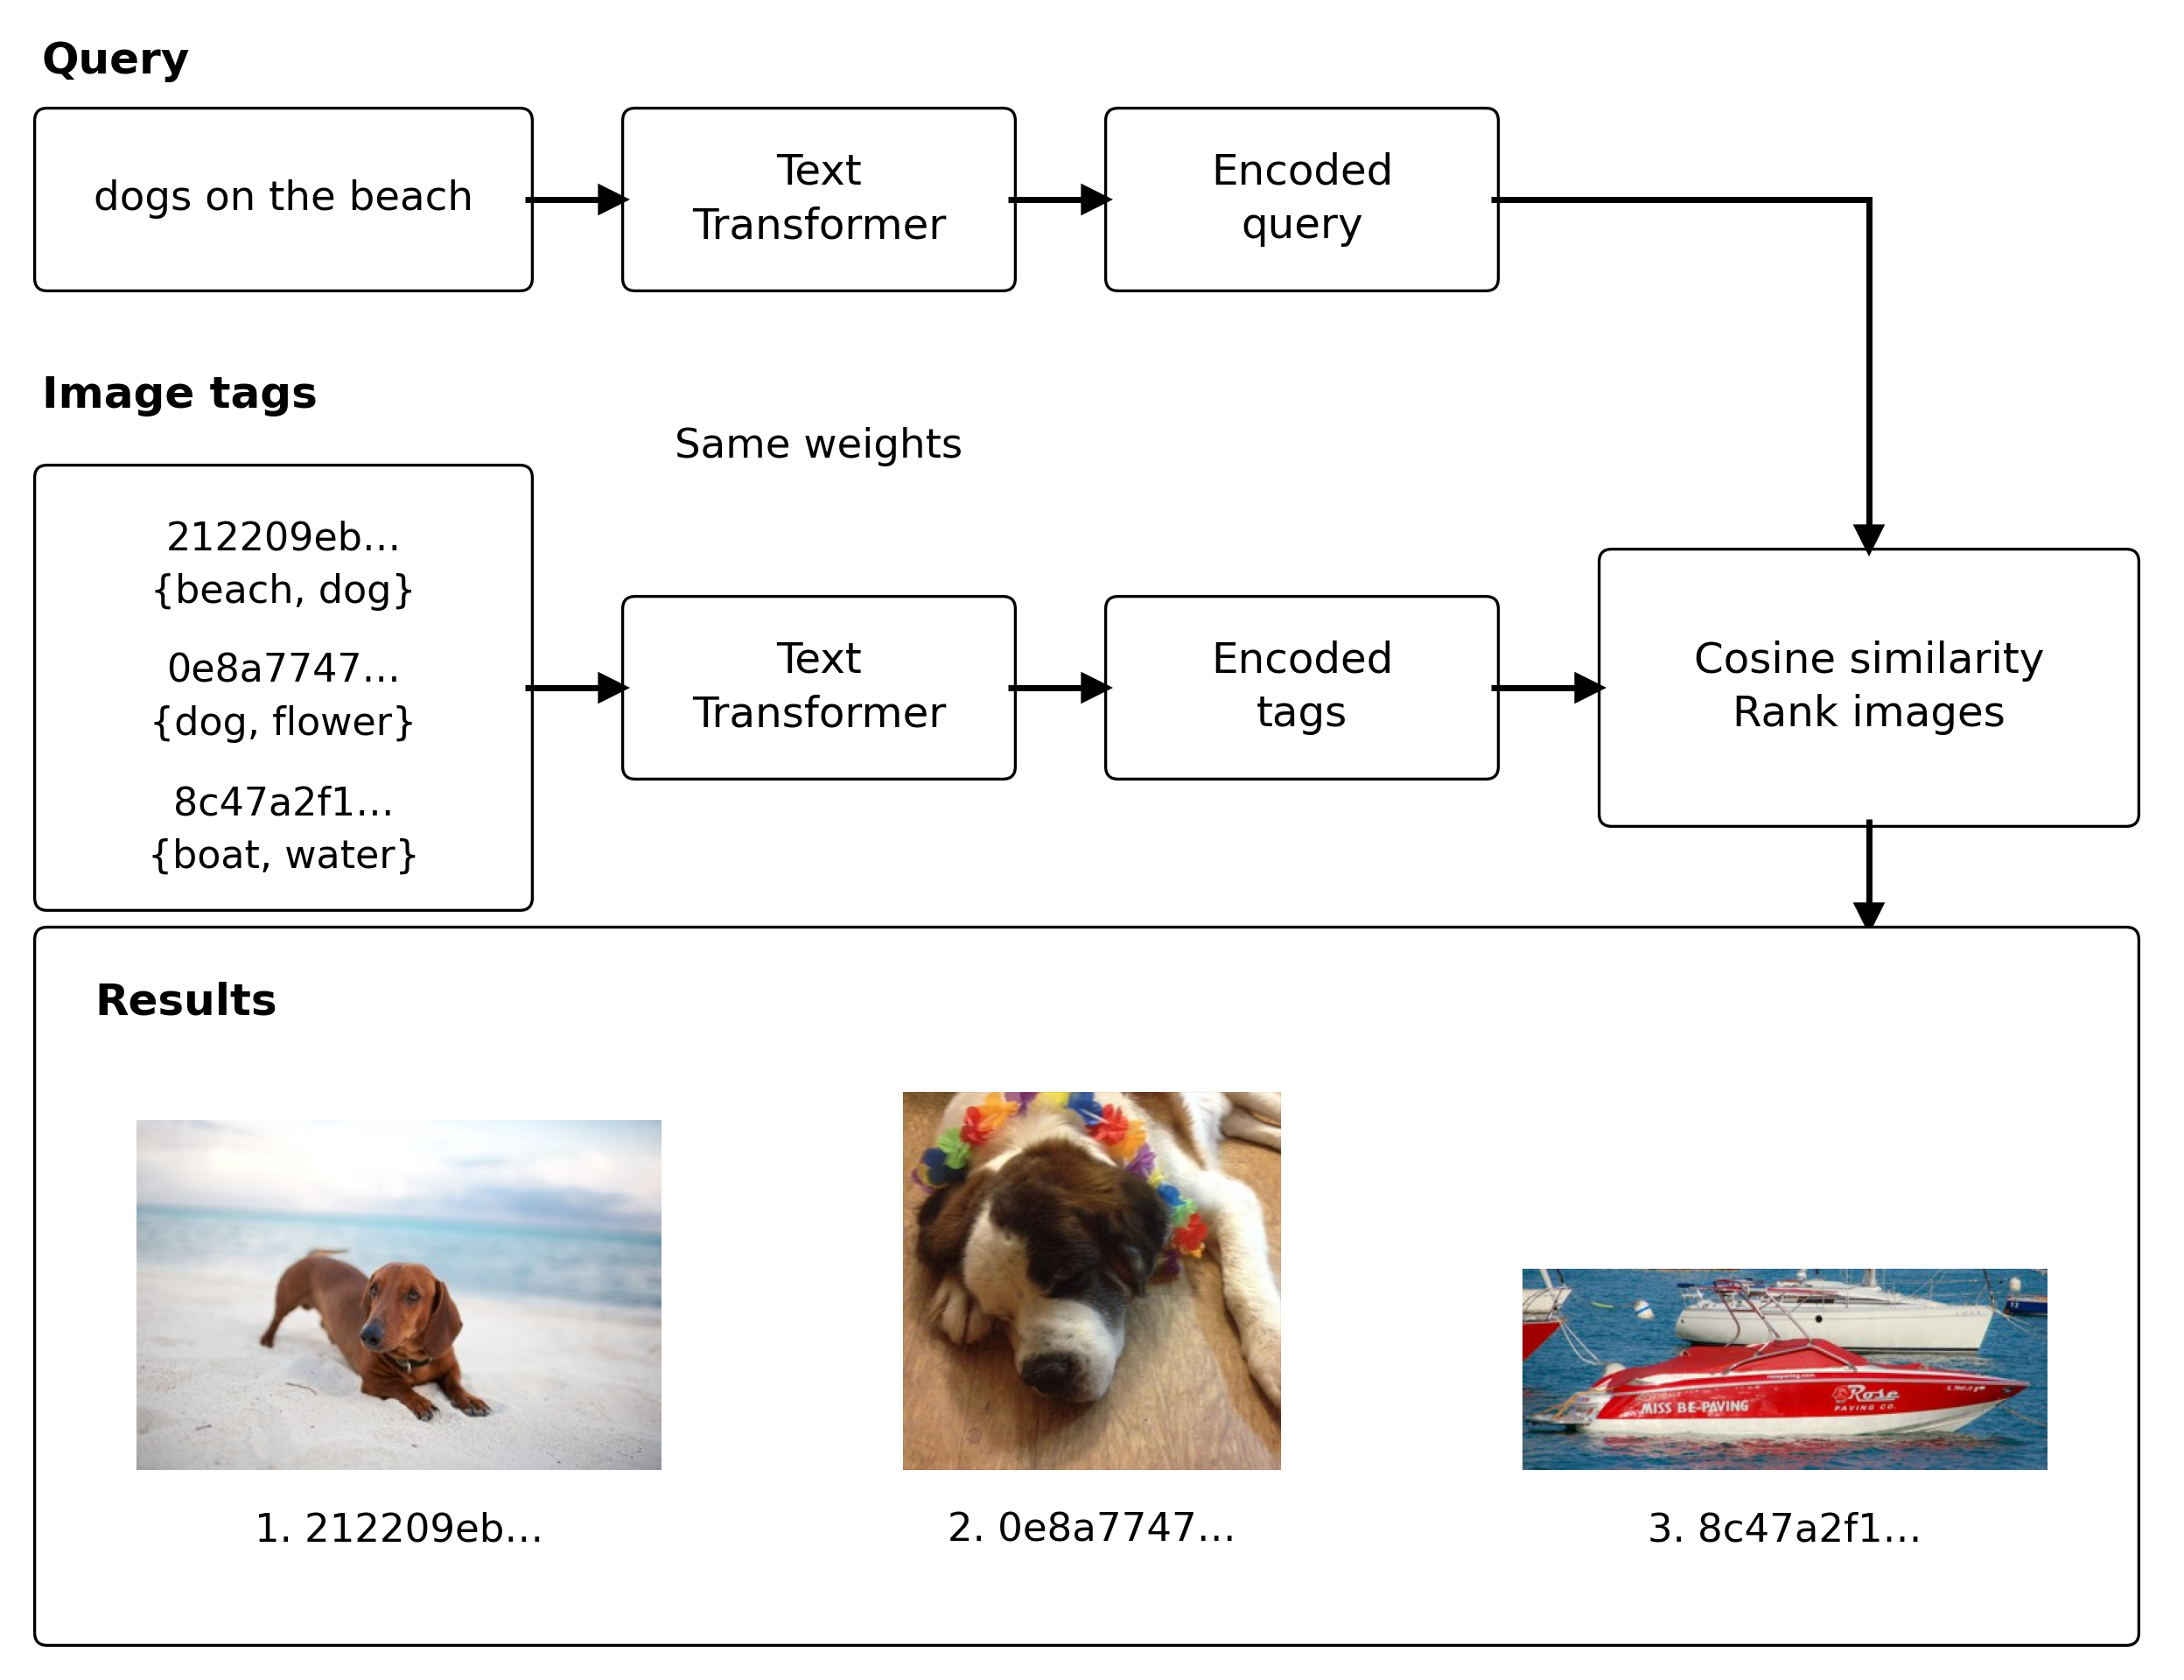

</div>

**Figure 1. Image retrieval.** Example ranking. Photos ([CC BY 2.0](https://creativecommons.org/licenses/by/2.0/), resized): [ToddonFlickr, “0174”](https://www.flickr.com/photos/toddneville/3497407627), [buyalex, “Piccard got lei’d and now he’s tired.”](https://www.flickr.com/photos/buyalex/9792565144), and [pulaw, `_MG_0371`](https://www.flickr.com/photos/pulaw/7182648693/). Full records are in catalog.json.

Encode query text and image tags with the same Transformer. The display helper looks up photos using ranked IDs. A photo may show objects that are missing from its tag list.

#### Positions (8 points)
Complete `forward` and `compute_mask` using learned token and position embeddings. See Problem 1(a).

In [ ]:
# GRADED: code
# Adapted from François Chollet's second edition listings (MIT).
# Copyright 2017-present François Chollet. See sources/CHOLLET-CODE-LICENSE.txt.
from hw3lib.runtime import torch,nn,np
from hw3lib.attention import BookAttention

class PositionalEmbedding(nn.Module):
    """Book 11.24: learned token+position vectors. IDs long (B,T). pad0/OOV1.
    1<=T<=sequence_length. IDs in [0,vocab_size). Return (B,T,D).
    compute_mask returns bool IDs!=0. Keep the supplied constructors.
    """
    def __init__(self,sequence_length,vocab_size,embed_dim):
        super().__init__();self.sequence_length=sequence_length
        self.token_embeddings=nn.Embedding(vocab_size,embed_dim)
        self.position_embeddings=nn.Embedding(sequence_length,embed_dim)
        nn.init.uniform_(self.token_embeddings.weight,-.05,.05)
        nn.init.uniform_(self.position_embeddings.weight,-.05,.05)
    def forward(self,inputs):
        # BEGIN TODO positions
        raise NotImplementedError('Complete positions')
        # END TODO
    def compute_mask(self,inputs):
        # BEGIN TODO token_mask
        raise NotImplementedError('Complete token_mask')
        # END TODO



#### Encoder (12 points)
Apply attention and FF with residual additions and postnormalization. See Problem 1(b).

In [ ]:
# GRADED: code
class TransformerEncoder(nn.Module):
    """Book 11.21: attention -> residual postnormalization -> FF -> residual postnormalization.
    inputs float (B,T,D). mask bool (B,T), True=valid key, or None.
    Return (B,T,D). use supplied attention/dense_proj/layernorm_1/2.
    BookAttention head_dim=D. LayerNorm eps=1e-3. No dropout.
    """
    def __init__(self,embed_dim,dense_dim,num_heads):
        super().__init__()
        self.attention=BookAttention(embed_dim,num_heads)
        self.dense_proj=nn.Sequential(nn.Linear(embed_dim,dense_dim),nn.ReLU(),nn.Linear(dense_dim,embed_dim))
        self.layernorm_1=nn.LayerNorm(embed_dim,eps=1e-3)
        self.layernorm_2=nn.LayerNorm(embed_dim,eps=1e-3)
    def forward(self,inputs,mask=None):
        # BEGIN TODO encoder
        raise NotImplementedError('Complete encoder')
        # END TODO



#### Retriever (10 points)
Encode valid tokens, pool their vectors, and normalize the result. See Problem 1(c).

In [ ]:
# GRADED: code
class TextRetriever(nn.Module):
    """Shared Transformer encodes queries and CANONICAL tag strings.
    tokens long (B,T), pad0/OOV1. Return float (B,D). Supplied catalog helper
    sorts/deduplicates tags BEFORE vectorization. query order is preserved.
    Pool = sum(valid*h)/max(count,1). output=pool/max(||pool||2,1e-8).
    All pad -> exact zero, trailing pads must not change embeddings.
    """
    def __init__(self,vocab_size,sequence_length=20,embed_dim=32,dense_dim=64,num_heads=2):
        super().__init__()
        self.embedding=PositionalEmbedding(sequence_length,vocab_size,embed_dim)
        self.encoder=TransformerEncoder(embed_dim,dense_dim,num_heads)
    def forward(self,tokens):
        # BEGIN TODO retriever
        raise NotImplementedError('Complete retriever')
        # END TODO



#### Ranking (10 points)
Return catalog indices and cosine scores with stable ID ordering for ties. See Problem 1(d).

In [ ]:
# GRADED: code
def retrieve_topk(query_vectors,key_vectors,image_ids,k):
    """Return (indices,scores), each (Q,k), into original catalog order.
    Finite float vectors (Q,D),(N,D). unique string IDs length N. 1<=k<=N.
    cosine=dot(q/max(||q||,1e-8),key/max(||key||,1e-8)). zero vectors score0.
    Sort by (-cosine,image_id) using EXACT ties, lexicographic string IDs.
    No rounding/tolerance buckets. No input mutation. NumPy allowed here.
    Tensor/ndarray returns accepted. Inputs CPU tensors or NumPy arrays.
    """
    # BEGIN TODO ranking
    raise NotImplementedError('Complete ranking')
    # END TODO



#### Questions (10 points)
Use the complete prompts and options in HW3.pdf.

| Variable | Points | PDF item |
|:---|---:|:---|
| `Q1_FIGURE_SCORES` | 3 | 1(e)1 |
| `Q1_TIED_IDS` | 1 | 1(e)2 |
| `Q1_PROBABILITIES` | 2 | 1(e)3 |
| `Q1_PAYLOAD` | 2 | 1(e)4 |
| `Q1_SYNONYM` | 2 | 1(e)5 |

In [ ]:
# GRADED: answers
Q1_FIGURE_SCORES=None
Q1_TIED_IDS=None
Q1_PROBABILITIES=None
Q1_PAYLOAD=None
Q1_SYNONYM=None


### Problem 2 (50 points)

<div style="max-width:800px">

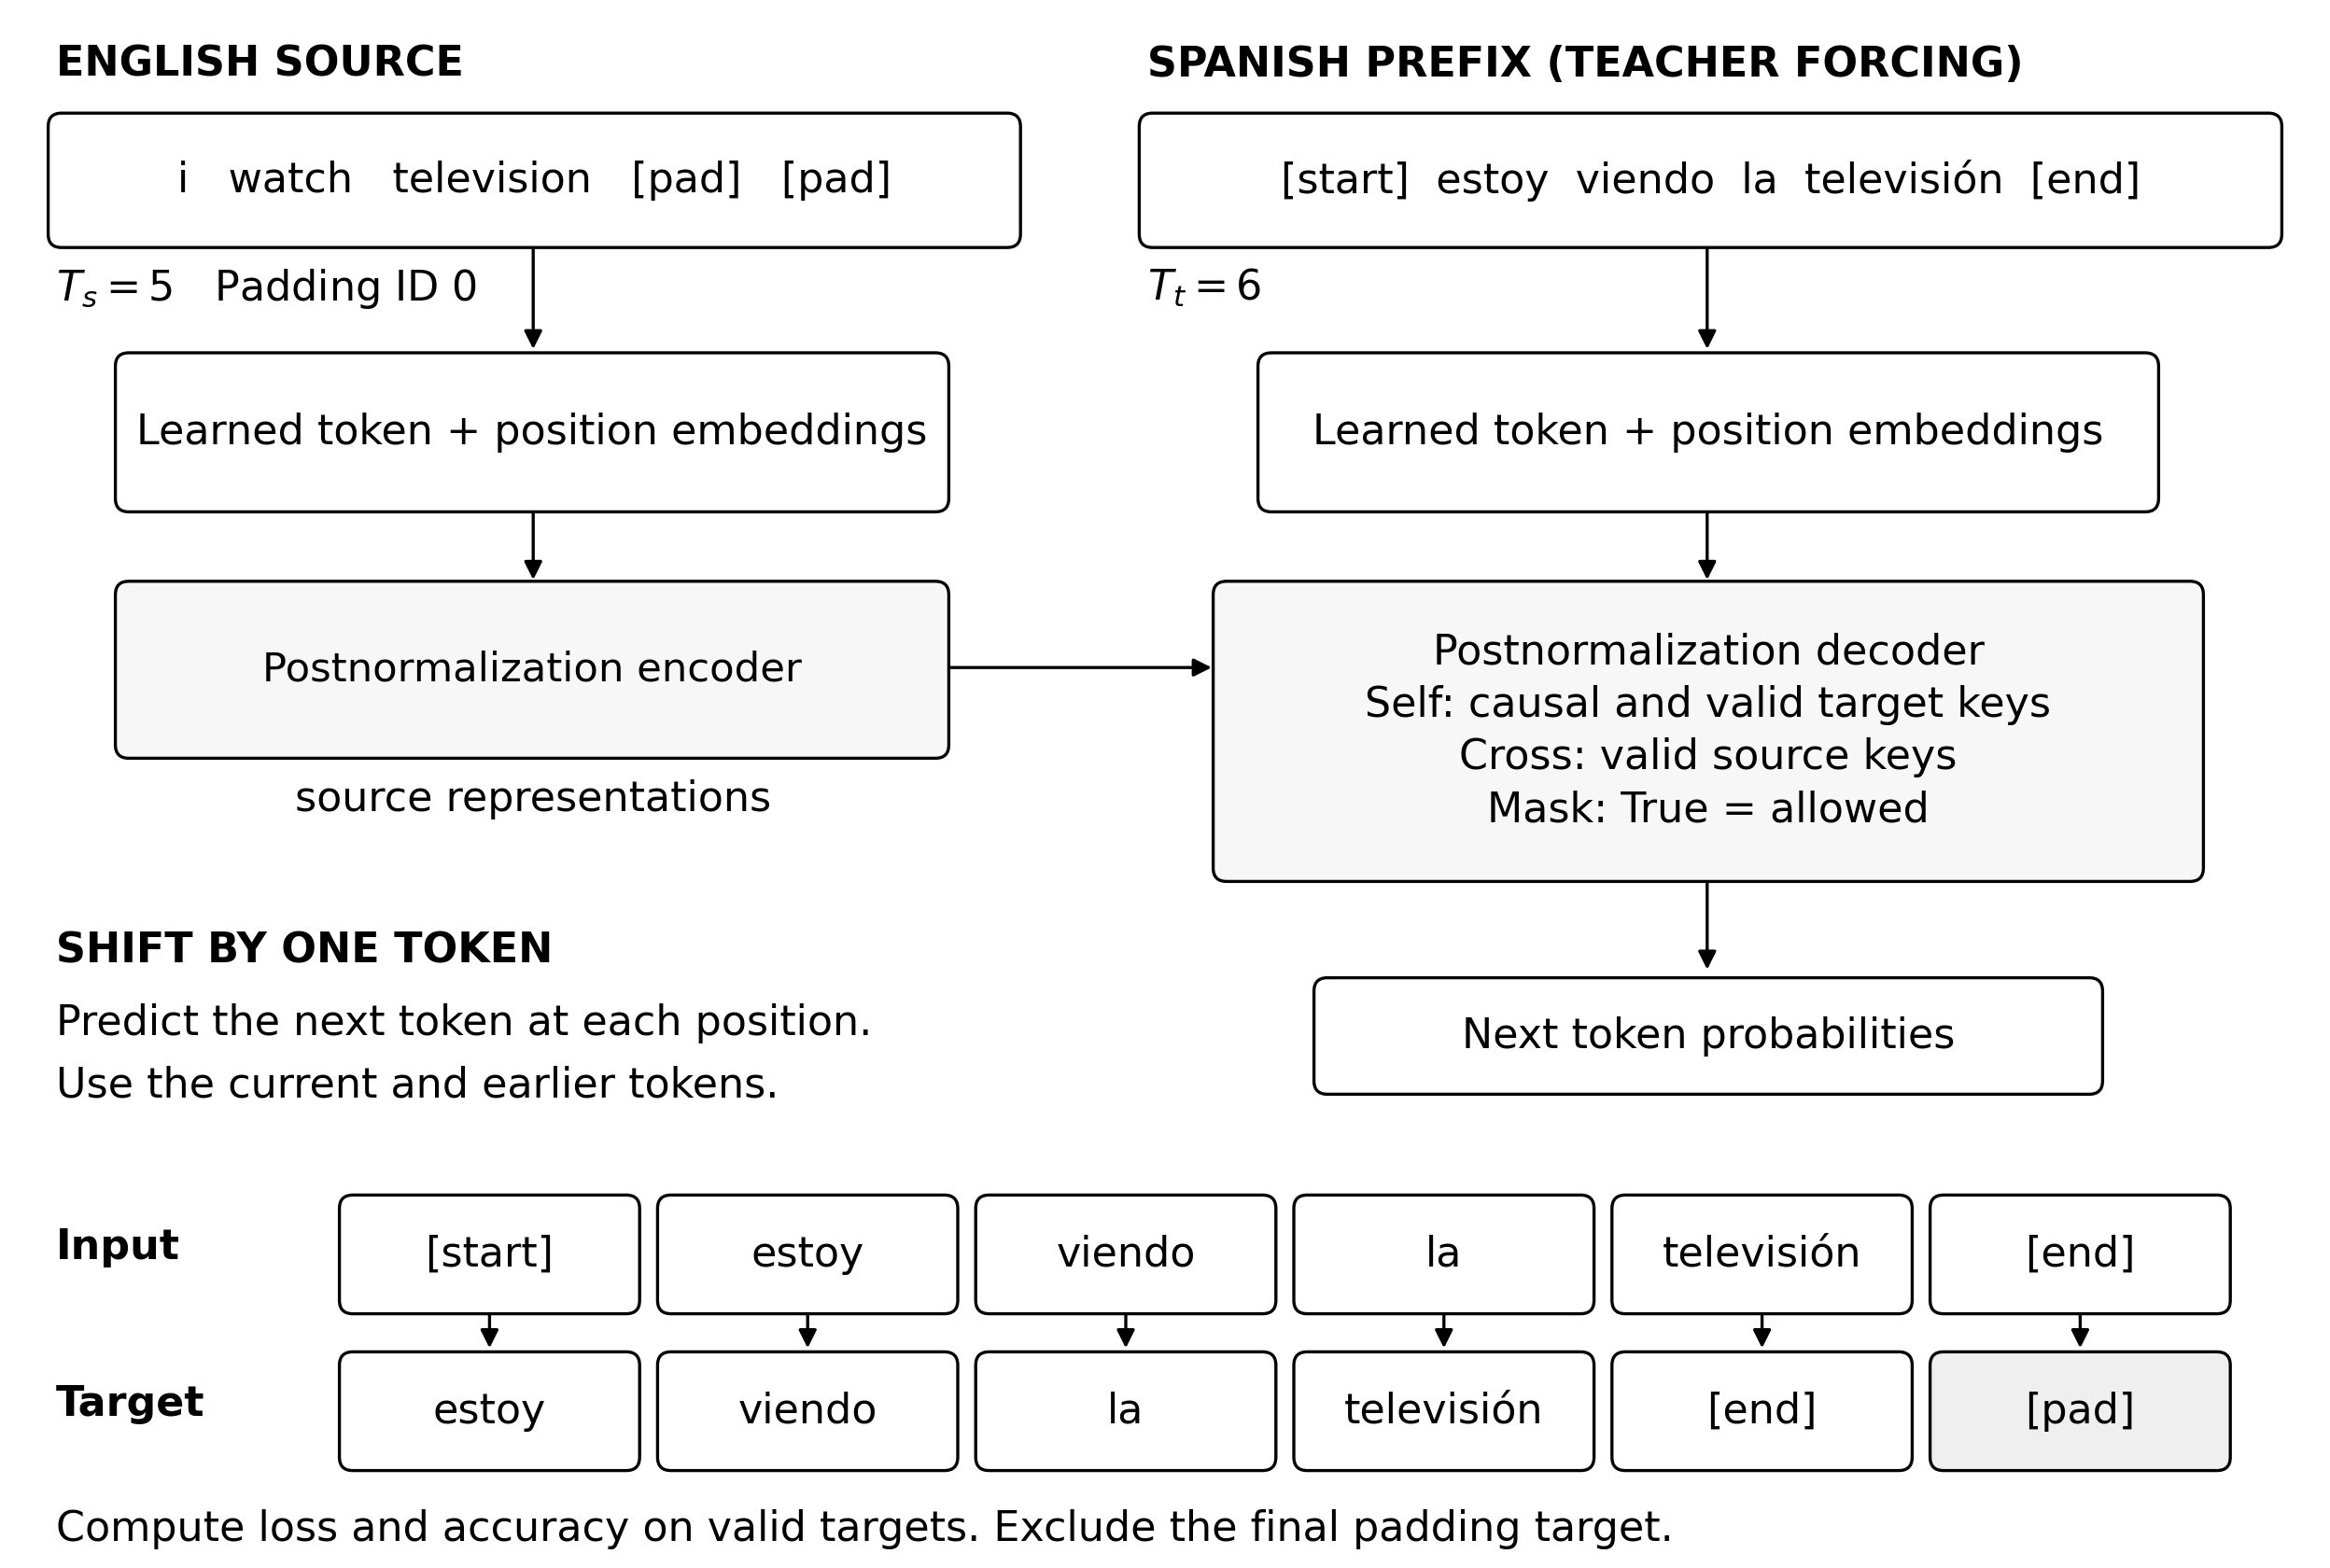

</div>

**Figure 2. English to Spanish translation.** Teacher forcing for the validation pair “I watch television.” → “Estoy viendo la televisión.” ManyThings and Tatoeba contributors, CC BY 2.0 FR.

Use the supplied encoder and decoder model to translate English to Spanish. Follow the mask definitions and metric equations in the handout.

#### Masks (10 points)
Build boolean encoder, self attention and cross attention masks. True means allowed. See Problem 2(a).

In [ ]:
# GRADED: code
def build_attention_masks(encoder_tokens,decoder_tokens):
    """Return (encoder_mask,self_mask,cross_mask), bool True=allowed.
    long inputs (B,Ts),(B,Tt), pad0. Ts,Tt>=1, every source has nonpad.
    Encoder (B,1,Ts): source key!=0. Self (B,Tt,Tt): j<=i AND tgt key!=0.
    Cross (B,Tt,Ts): source key!=0, NO causality. Query padding need not
    be zeroed. masked loss ignores pad targets. Unequal Ts,Tt supported.
    """
    # BEGIN TODO masks
    raise NotImplementedError('Complete masks')
    # END TODO



#### Decoder (15 points)
Apply self attention, source cross attention and FF in sequence with postnormalization. See Problem 2(b).

In [ ]:
# GRADED: code
class TransformerDecoder(nn.Module):
    """Book 11.33-11.35, explicit mask routing. inputs (B,Tt,D),
    encoder_outputs (B,Ts,D). self_mask bool (B,Tt,Tt), cross_mask (B,Tt,Ts),
    True=allowed. either may be None. Three residual postnormalization sublayers:
    self attention, source cross attention, FF. Return (B,Tt,D).
    BookAttention head_dim=D, LayerNorm eps=1e-3. Constructors supplied.
    """
    def __init__(self,embed_dim,dense_dim,num_heads):
        super().__init__()
        self.attention_1=BookAttention(embed_dim,num_heads)
        self.attention_2=BookAttention(embed_dim,num_heads)
        self.dense_proj=nn.Sequential(nn.Linear(embed_dim,dense_dim),nn.ReLU(),nn.Linear(dense_dim,embed_dim))
        self.layernorm_1=nn.LayerNorm(embed_dim,eps=1e-3)
        self.layernorm_2=nn.LayerNorm(embed_dim,eps=1e-3)
        self.layernorm_3=nn.LayerNorm(embed_dim,eps=1e-3)
    def get_causal_attention_mask(self,inputs):
        b,t,_=inputs.shape;a=torch.arange(t,device=inputs.device)
        return (a[:,None]>=a[None,:])[None,:,:].expand(b,-1,-1)
    def forward(self,inputs,encoder_outputs,self_mask=None,cross_mask=None):
        # BEGIN TODO decoder
        raise NotImplementedError('Complete decoder')
        # END TODO



#### Metrics (10 points)
Compute token loss and accuracy using only valid targets. Preserve loss gradients. See Problem 2(c).

In [ ]:
# GRADED: code
def masked_token_metrics(targets,probabilities):
    """Return (loss,accuracy), 0-D float tensors. differentiable loss.
    targets long (B,T), normalized finite probability rows (B,T,V).
    m=(targets!=0). loss=sum(-log(clip(p_true,1e-7,1-1e-7))*m)/sum(m).
    acc=sum((argmax(p)==targets)*m)/sum(m). Allpad -> (0,0) with finite
    backward gradients. OOV1 counts. denominator counts valid tokens only.
    """
    # BEGIN TODO metrics
    raise NotImplementedError('Complete metrics')
    # END TODO



#### Greedy decoding (10 points)
Generate a token sequence using the prefix buffer and the stopping rules. See Problem 2(d).

In [ ]:
# GRADED: code
def greedy_decode(model,source_tokens,start_id,end_id,max_length):
    """One source long (1,Ts). returns list[int]. CPU inputs/model.
    Model signature: model(source_tokens,decoder_tokens)->probs (1,L,V).
    Allocate zero long decoder buffer (1,L), start in slot0. At step i,
    argmax probs[0,i] (lowest ID tie). end OR pad0 stops without appending.
    Else append and copy to buffer[0,i+1] if space remains. At most L steps.
    Exclude initial start/terminating end/pad. a later emitted start is an
    ordinary generated token. Use model.eval() + no_grad, restore original
    model.training flag even on error. Do not mutate source/model parameters.
    Valid: L>=1, positive distinct start/end IDs, source has nonpad.
    """
    # BEGIN TODO greedy
    raise NotImplementedError('Complete greedy')
    # END TODO


#### Questions (5 points)
Use the complete prompts and options in HW3.pdf.

| Variable | Points | PDF item |
|:---|---:|:---|
| `Q2_SHIFT` | 2 | 2(e)1 |
| `Q2_MASK` | 1 | 2(e)2 |
| `Q2_ACCURACY` | 1 | 2(e)3 |
| `Q2_POSITIONS` | 1 | 2(e)4 |

In [ ]:
# GRADED: answers
Q2_SHIFT=None
Q2_MASK=None
Q2_ACCURACY=None
Q2_POSITIONS=None


In [ ]:
check()

### Examples (optional)
Set `RUN_DEMOS=True` to train the examples. Inspect the retrieval results and compare generated translations with their references. The helpers load your saved definitions.

In [ ]:
RUN_DEMOS = False  # Set True to run the examples.
if RUN_DEMOS:
    from hw3lib.experiment import train_retrieval, show_retrieval, train_translation, translate
    student, _ = load_submission("hw3.ipynb")
    retrieval_model, retrieval_info, retrieval_run = train_retrieval(student)
    print(retrieval_run)
    show_retrieval(student, retrieval_model, retrieval_info, "dogs on the beach")
    show_retrieval(student, retrieval_model, retrieval_info, "a puppy on the seaside")
    translation_model, translation_info, translation_run = train_translation(student, epochs=25)
    print(translation_run)
    for english, spanish in translation_info['raw']['validation'][:5]:
        print("English:", english)
        print("Reference:", spanish)
        print("Generated:", translate(student, translation_model, translation_info, english))